# TASK : 1

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine

data = load_wine(as_frame=True)
df = data.frame

print(df.shape)
display(df.head())
print(df.isnull().sum())
print(df.describe())

(178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64
          alcohol  malic_acid         ash  alcalinity_of_ash   magnesium  \
count  178.000000  178.000000  178.000000         178.000000  178.000000   
mean    13.000618    2.336348    2.366517          19.494944   99.741573   
std      0.811827    1.117146    0.274344           3.339564   14.282484   
min     11.030000    0.740000    1.360000          10.600000   70.000000   
25%     12.362500    1.602500    2.210000          17.200000   88.000000   
50%     13.050000    1.865000    2.360000          19.5

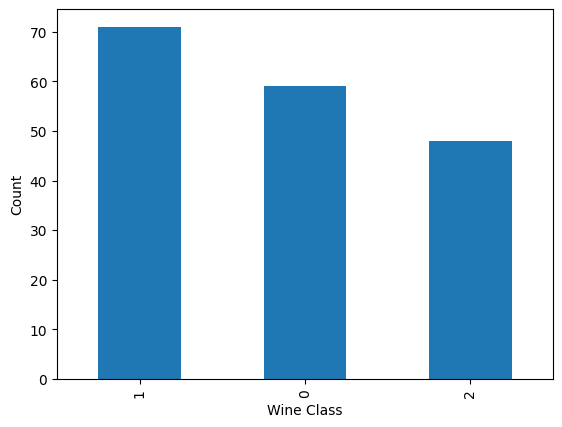

In [60]:
df['target'].value_counts().plot(kind='bar')
plt.xlabel('Wine Class')
plt.ylabel('Count')
plt.show()

In [59]:
print(df[['proline', 'hue']].describe())

           proline         hue
count   178.000000  178.000000
mean    746.893258    0.957449
std     314.907474    0.228572
min     278.000000    0.480000
25%     500.500000    0.782500
50%     673.500000    0.965000
75%     985.000000    1.120000
max    1680.000000    1.710000


In [58]:
X = df.drop('target', axis=1)
y = df['target']
print(X.shape, y.shape)

(178, 13) (178,)


In [57]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [56]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [55]:
from tensorflow.keras.utils import to_categorical

y_train = to_categorical(y_train, num_classes=3)
y_test = to_categorical(y_test, num_classes=3)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (142, 13)
X_test: (36, 13)
y_train: (142, 3, 3)
y_test: (36, 3, 3)


In [54]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential([
    Dense(16, activation='relu', input_shape=(13,)),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [53]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,163 (4.55 KB)

 Trainable params: 387 (1.51 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 776 (3.04 KB)

In [52]:
history = model.fit(
    X_train, y_train,
    epochs=60,
    batch_size=8,
    validation_split=0.2,
    verbose=1
)

Epoch 1/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.4425 - loss: 1.0932 - val_accuracy: 0.6207 - val_loss: 0.9804
Epoch 2/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5487 - loss: 0.9987 - val_accuracy: 0.6552 - val_loss: 0.8745
Epoch 3/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6283 - loss: 0.9165 - val_accuracy: 0.7241 - val_loss: 0.7920
Epoch 4/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7257 - loss: 0.8443 - val_accuracy: 0.7586 - val_loss: 0.7229
Epoch 5/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7611 - loss: 0.7800 - val_accuracy: 0.7586 - val_loss: 0.6508
Epoch 6/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7788 - loss: 0.7200 - val_accuracy: 0.8276 - val_loss: 0.5849
Epoch 7/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7965 - loss: 0.6640 - val_accuracy: 0.8276 - val_loss: 0.5279
Epoch 8/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7965 - loss: 0.6092 - val_accuracy: 0.8966 - val_lo

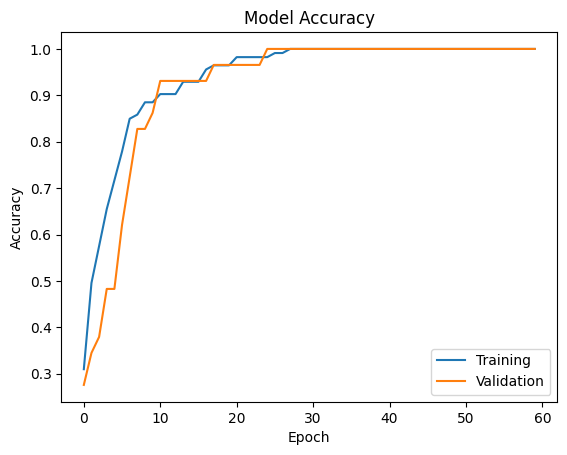

In [51]:
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

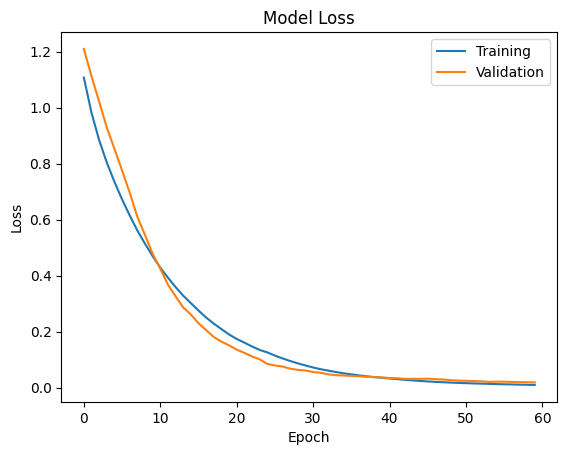

In [24]:
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [25]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)

print("Test Accuracy:", model.evaluate(X_test, y_test, verbose=0)[1])
print(classification_report(y_true, y_pred))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Test Accuracy: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



In [27]:
import seaborn as sns

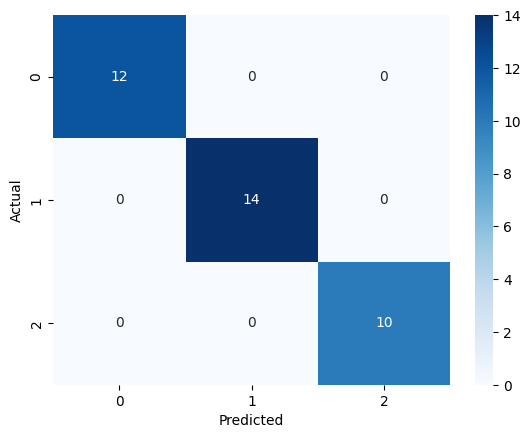

In [28]:
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [29]:
model.save("ann_wine_model.h5")
print("Model saved successfully!")

Model saved successfully!


1. What does each layer do?
- Input layer: Accepts 13 chemical features.
- Hidden layer 1: Learns patterns using 16 neurons and ReLU.
- Hidden layer 2: Learns more complex patterns using 8 neurons and ReLU.
- Output layer: Uses 3 neurons to predict the three wine classes.
2. Why use Softmax instead of Sigmoid?

Softmax produces probabilities for all three classes that add up to 1. It is suitable for multi-class classification where each wine belongs to one class.

3. Why use categorical cross-entropy?

The target has three classes represented using one-hot encoding. Categorical cross-entropy measures the difference between the predicted probabilities and the correct class.

4. What do the 3 output numbers add up to?

The three Softmax output probabilities add up to approximately 1 (100%).

# TASK : 2

In [30]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

In [33]:
images = [
    data.astronaut(),
    data.chelsea(),
    data.coffee(),
    data.rocket(),
    cv2.cvtColor(cv2.imread(r"D:\Deep_Learning\DL_FINAL\images\WhatsApp Image 2026-09-13 at 12.55.01 PM.jpeg"), cv2.COLOR_BGR2RGB)
]

1 Shape: (512, 512, 3) Type: uint8 Min: 0 Max: 255 Brightness: 114.59900410970052


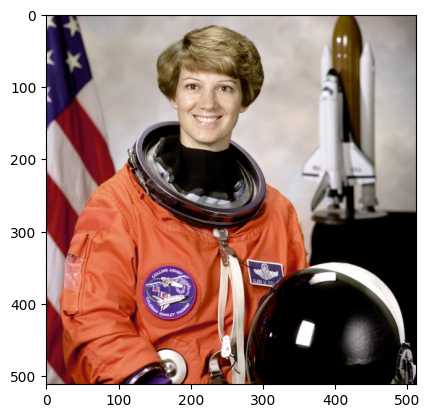

2 Shape: (300, 451, 3) Type: uint8 Min: 0 Max: 231 Brightness: 115.30514166050752


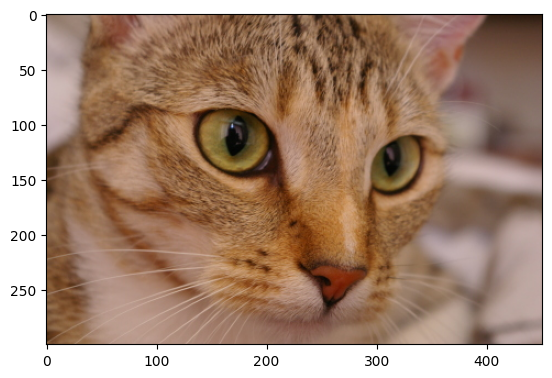

3 Shape: (400, 600, 3) Type: uint8 Min: 0 Max: 255 Brightness: 98.61595416666667


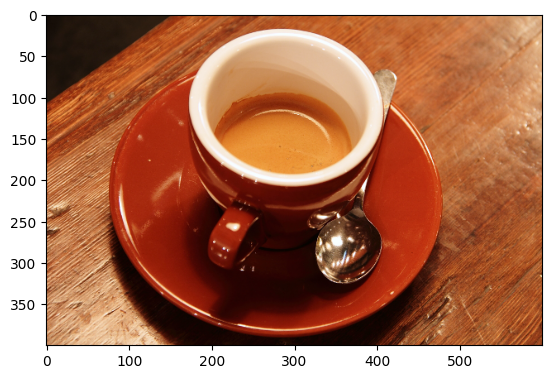

4 Shape: (427, 640, 3) Type: uint8 Min: 0 Max: 255 Brightness: 65.27705893832943


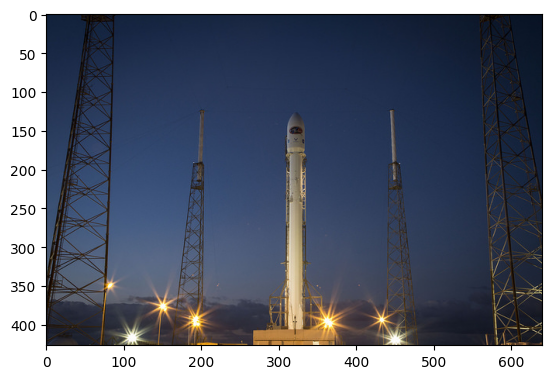

5 Shape: (1280, 960, 3) Type: uint8 Min: 0 Max: 255 Brightness: 165.37039442274306


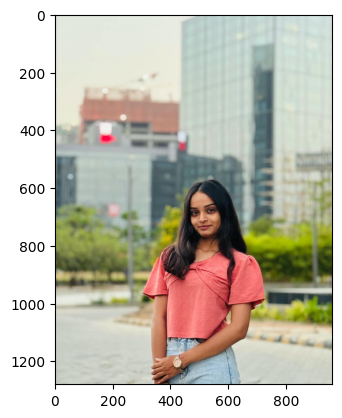

In [34]:
for i, img in enumerate(images):
    print(i+1, "Shape:", img.shape, "Type:", img.dtype,
          "Min:", img.min(), "Max:", img.max(),
          "Brightness:", img.mean())

    plt.imshow(img)
    plt.show()

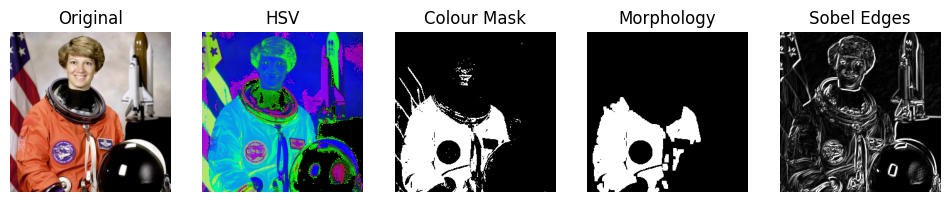

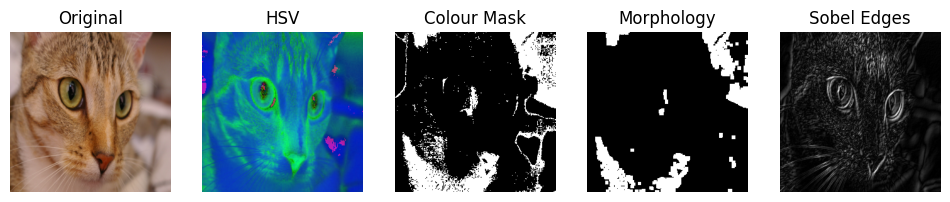

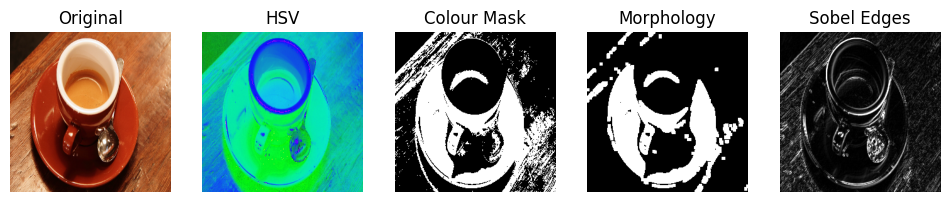

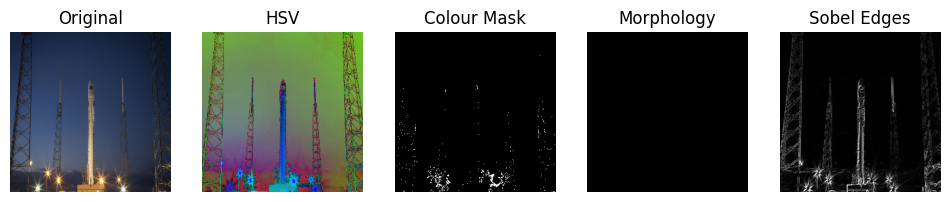

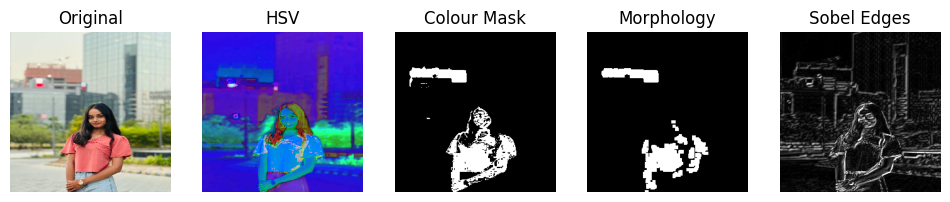

In [35]:
kernel = np.ones((5, 5), np.uint8)

for img in images:
    img = cv2.resize(img, (256, 256))
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)

    lower = np.array([0, 50, 50])
    upper = np.array([10, 255, 255])
    mask = cv2.inRange(hsv, lower, upper)

    clean = cv2.dilate(cv2.erode(mask, kernel), kernel)

    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    sx = cv2.Sobel(gray, cv2.CV_64F, 1, 0)
    sy = cv2.Sobel(gray, cv2.CV_64F, 0, 1)
    edges = cv2.convertScaleAbs(cv2.addWeighted(sx, 0.5, sy, 0.5, 0))

    plt.figure(figsize=(12, 3))
    for i, (title, result) in enumerate([
        ("Original", img), ("HSV", hsv), ("Colour Mask", mask),
        ("Morphology", clean), ("Sobel Edges", edges)
    ]):
        plt.subplot(1, 5, i+1)
        plt.imshow(result, cmap='gray' if len(result.shape) == 2 else None)
        plt.title(title)
        plt.axis('off')
    plt.show()

In [63]:
face_cascade = cv2.CascadeClassifier('haarcascade_frontalface_default.xml')
print("Cascade loaded:", not face_cascade.empty())

Cascade loaded: True


Faces detected: 1


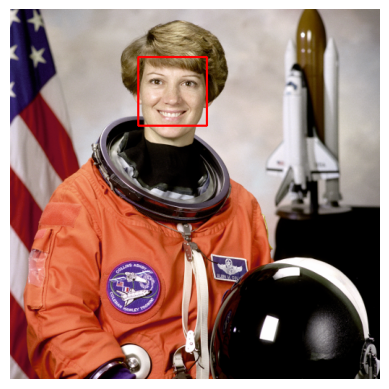

Faces detected: 0


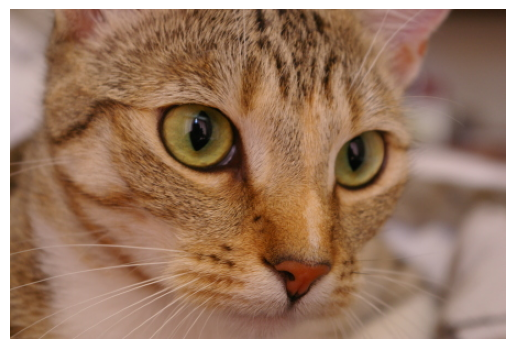

Faces detected: 0


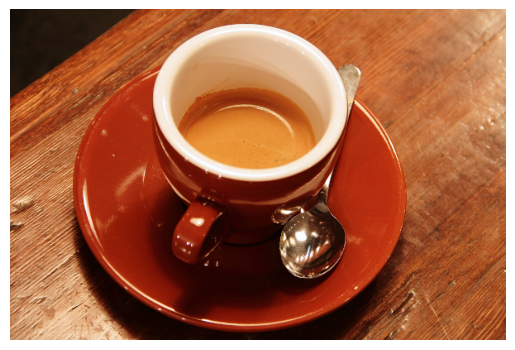

Faces detected: 0


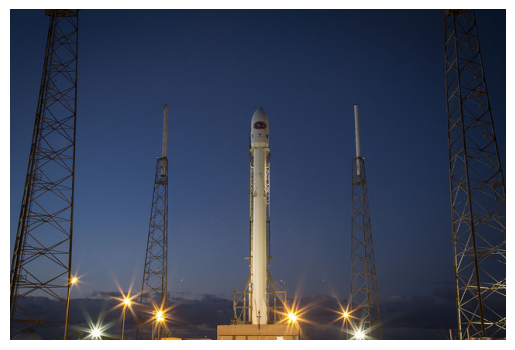

Faces detected: 2


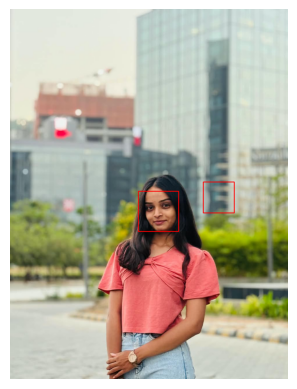

In [66]:
import cv2
import matplotlib.pyplot as plt

face_cascade = cv2.CascadeClassifier('haarcascade_frontalface_default.xml')

for img in images:
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    faces = face_cascade.detectMultiScale(gray, 1.1, 5)

    result = img.copy()
    for (x, y, w, h) in faces:
        cv2.rectangle(result, (x, y), (x+w, y+h), (255, 0, 0), 2)

    print("Faces detected:", len(faces))
    plt.imshow(result)
    plt.axis('off')
    plt.show()

In [67]:
img = images[0]
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

for n in [2, 5, 8]:
    faces = face_cascade.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=n
    )
    print("minNeighbors:", n, "| Faces:", len(faces))

minNeighbors: 2 | Faces: 1
minNeighbors: 5 | Faces: 1
minNeighbors: 8 | Faces: 1


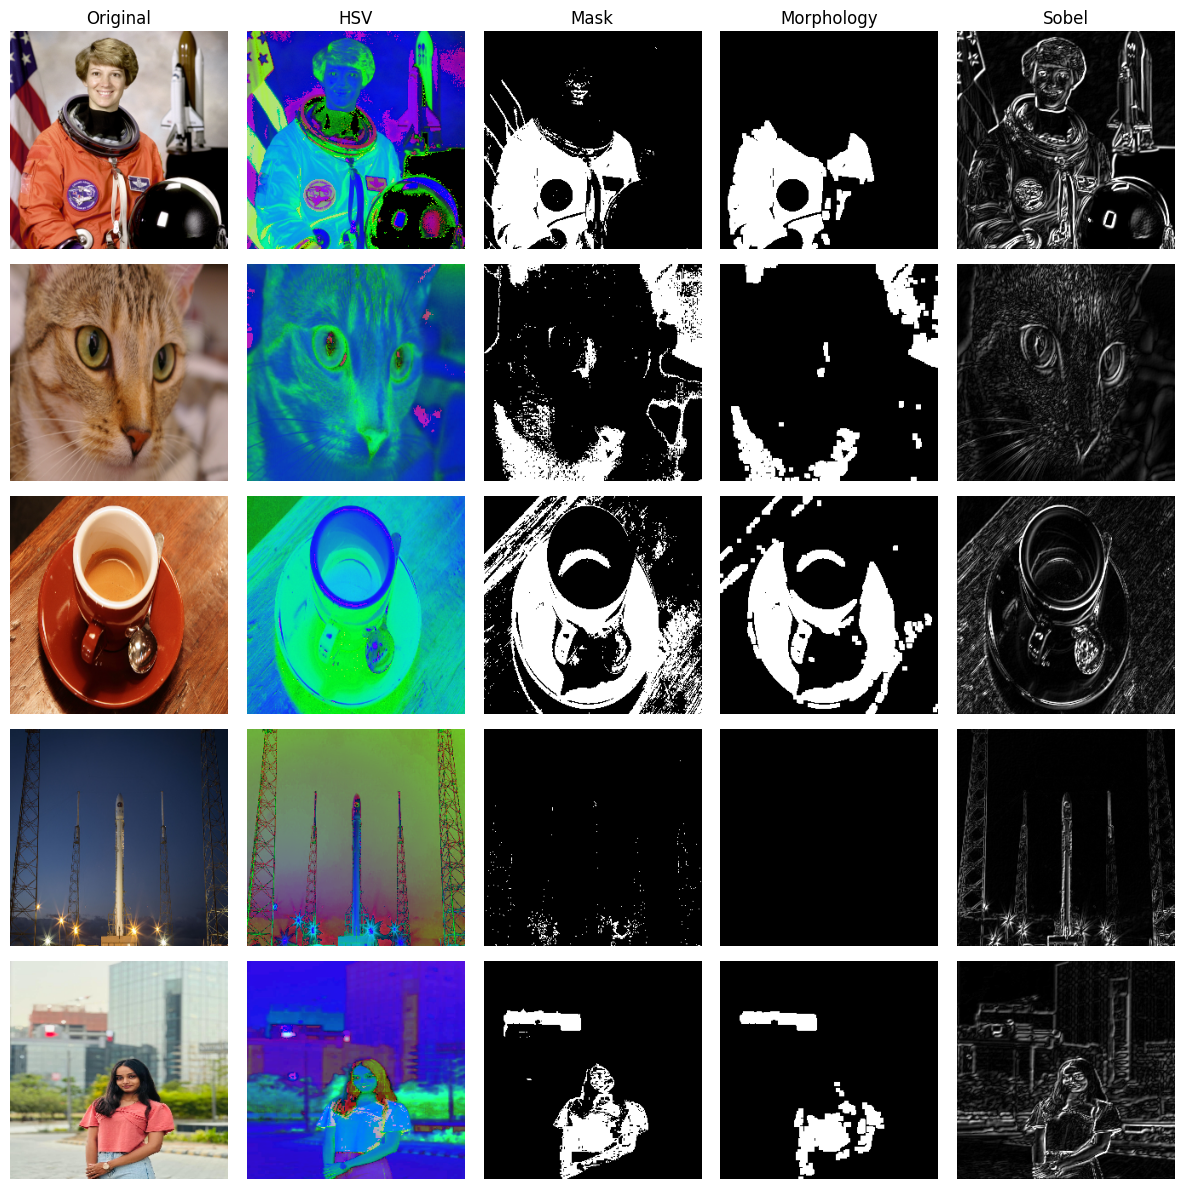

In [68]:
fig, axes = plt.subplots(5, 5, figsize=(12, 12))

for row, img in enumerate(images):
    img = cv2.resize(img, (256, 256))
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    mask = cv2.inRange(hsv, np.array([0,50,50]), np.array([10,255,255]))
    clean = cv2.dilate(cv2.erode(mask, kernel), kernel)

    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    sx = cv2.Sobel(gray, cv2.CV_64F, 1, 0)
    sy = cv2.Sobel(gray, cv2.CV_64F, 0, 1)
    edges = cv2.convertScaleAbs(cv2.addWeighted(sx, .5, sy, .5, 0))

    results = [img, hsv, mask, clean, edges]

    for col, result in enumerate(results):
        axes[row, col].imshow(result, cmap='gray' if result.ndim == 2 else None)
        axes[row, col].axis('off')

for ax, title in zip(axes[0], ["Original", "HSV", "Mask", "Morphology", "Sobel"]):
    ax.set_title(title)

plt.tight_layout()
plt.show()

1. Why is HSV easier than BGR for colour selection?
HSV separates colour from brightness, making it easier to select a specific colour using a range.

2. What do erosion and dilation do?
- Erosion: Removes small white regions and shrinks white objects.
- Dilation: Expands white regions and fills small gaps.
3. How is a Haar Cascade different from a CNN?
A Haar Cascade uses predefined features and a trained classifier. A CNN learns features automatically from training data.

# TASK : 3

In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

X_train, y_train = X_train[:20000], y_train[:20000]
X_test, y_test = X_test[:4000], y_test[:4000]

print(X_train.shape, X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
(20000, 28, 28) (4000, 28, 28)


In [70]:
X_train = X_train / 255.0
X_test = X_test / 255.0

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

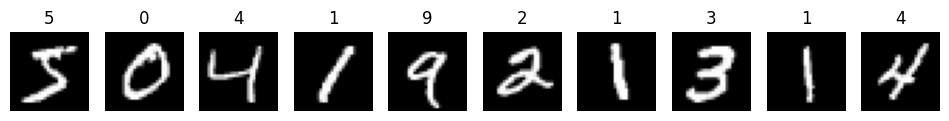

In [71]:
plt.figure(figsize=(12, 3))

for i in range(10):
    plt.subplot(1, 10, i+1)
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    plt.title(y_train[i])
    plt.axis("off")

plt.show()

In [72]:
cnn = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

cnn.compile(optimizer='adam',
            loss='categorical_crossentropy',
            metrics=['accuracy'])

cnn.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

In [73]:
ann = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

ann.compile(optimizer='adam',
            loss='categorical_crossentropy',
            metrics=['accuracy'])

ann.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [74]:
early_stop = EarlyStopping(
    monitor='val_loss', patience=2, restore_best_weights=True
)

hist_cnn = cnn.fit(
    X_train, y_train_cat,
    epochs=8, batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop]
)

Epoch 1/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8655 - loss: 0.4691 - val_accuracy: 0.9530 - val_loss: 0.1561
Epoch 2/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9593 - loss: 0.1283 - val_accuracy: 0.9685 - val_loss: 0.0960
Epoch 3/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9726 - loss: 0.0843 - val_accuracy: 0.9760 - val_loss: 0.0811
Epoch 4/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9797 - loss: 0.0637 - val_accuracy: 0.9730 - val_loss: 0.0785
Epoch 5/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9837 - loss: 0.0504 - val_accuracy: 0.9835 - val_loss: 0.0557
Epoch 6/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9876 - loss: 0.0399 - val_accuracy: 0.9865 - val_loss: 0.0450
Epoch 7/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9893 - loss: 0.0320 - val_accuracy: 0.9860 - val_loss: 0.0474
Epoch 8/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9901 - loss: 0.0306 - val_accuracy: 0.9870 - v

In [77]:
hist_ann = ann.fit(
    X_train, y_train_cat,
    epochs=8, batch_size=64,
    validation_split=0.1
)

Epoch 1/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8636 - loss: 0.4769 - val_accuracy: 0.9390 - val_loss: 0.2234
Epoch 2/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9431 - loss: 0.2003 - val_accuracy: 0.9545 - val_loss: 0.1664
Epoch 3/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9609 - loss: 0.1369 - val_accuracy: 0.9600 - val_loss: 0.1505
Epoch 4/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9710 - loss: 0.1017 - val_accuracy: 0.9640 - val_loss: 0.1237
Epoch 5/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9777 - loss: 0.0770 - val_accuracy: 0.9675 - val_loss: 0.1224
Epoch 6/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9837 - loss: 0.0565 - val_accuracy: 0.9645 - val_loss: 0.1363
Epoch 7/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9874 - loss: 0.0444 - val_accuracy: 0.9690 - val_loss: 0.1258
Epoch 8/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9920 - loss: 0.0328 - val_accuracy: 0.9640 - v

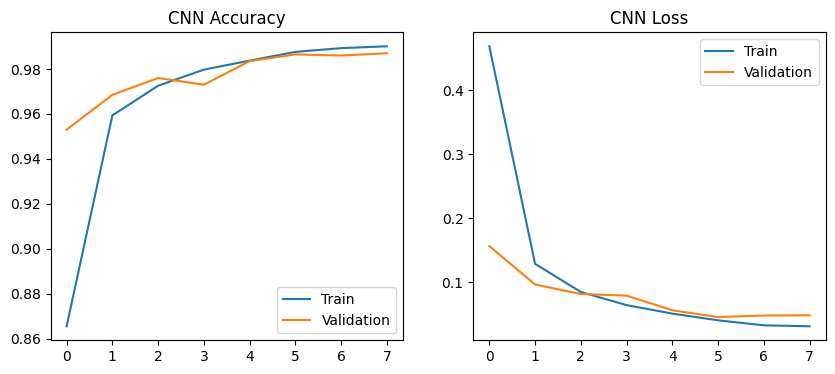

In [78]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(hist_cnn.history['accuracy'], label='Train')
plt.plot(hist_cnn.history['val_accuracy'], label='Validation')
plt.title('CNN Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist_cnn.history['loss'], label='Train')
plt.plot(hist_cnn.history['val_loss'], label='Validation')
plt.title('CNN Loss')
plt.legend()

plt.show()

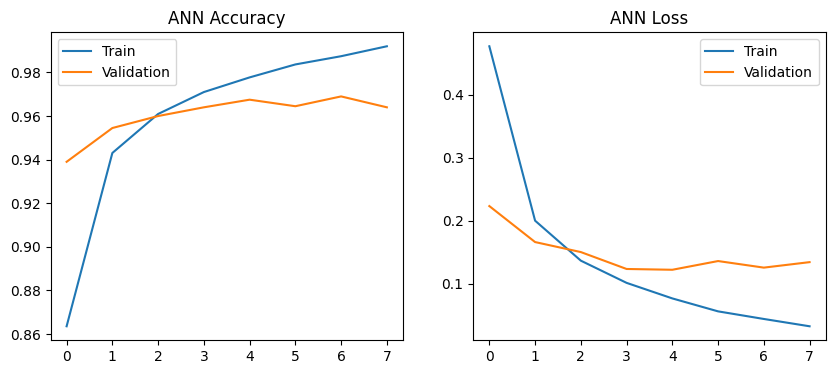

In [79]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(hist_ann.history['accuracy'], label='Train')
plt.plot(hist_ann.history['val_accuracy'], label='Validation')
plt.title('ANN Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist_ann.history['loss'], label='Train')
plt.plot(hist_ann.history['val_loss'], label='Validation')
plt.title('ANN Loss')
plt.legend()

plt.show()

In [80]:
cnn_loss, cnn_acc = cnn.evaluate(X_test, y_test_cat, verbose=0)
ann_loss, ann_acc = ann.evaluate(X_test, y_test_cat, verbose=0)

comparison = pd.DataFrame({
    'Model': ['CNN', 'ANN'],
    'Total Parameters': [cnn.count_params(), ann.count_params()],
    'Test Accuracy': [cnn_acc, ann_acc]
})

print(comparison)

  Model  Total Parameters  Test Accuracy
0   CNN             56714        0.97825
1   ANN            109386        0.95150


In [81]:
y_pred = np.argmax(cnn.predict(X_test, verbose=0), axis=1)

print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.98      0.99      0.98       370
           1       0.98      0.99      0.99       450
           2       0.98      0.98      0.98       418
           3       0.99      0.97      0.98       408
           4       0.99      0.97      0.98       418
           5       0.97      0.97      0.97       372
           6       0.98      0.98      0.98       378
           7       0.97      0.98      0.97       411
           8       0.98      0.97      0.98       384
           9       0.97      0.97      0.97       391

    accuracy                           0.98      4000
   macro avg       0.98      0.98      0.98      4000
weighted avg       0.98      0.98      0.98      4000



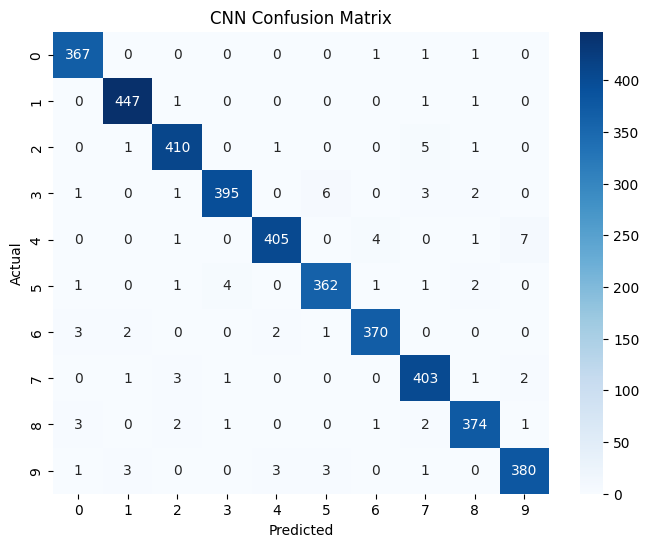

In [82]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CNN Confusion Matrix')
plt.show()

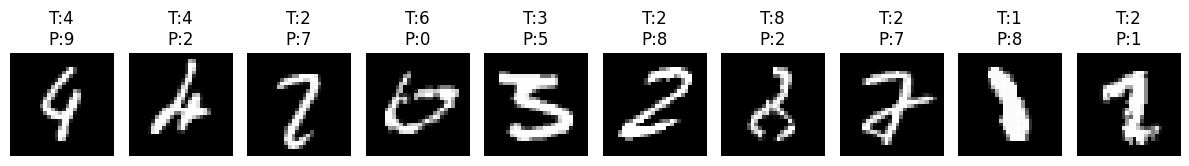

In [83]:
wrong = np.where(y_pred != y_test)[0][:10]

plt.figure(figsize=(12, 4))

for i, idx in enumerate(wrong):
    plt.subplot(1, 10, i+1)
    plt.imshow(X_test[idx].squeeze(), cmap='gray')
    plt.title(f'T:{y_test[idx]}\nP:{y_pred[idx]}')
    plt.axis('off')

plt.tight_layout()
plt.show()

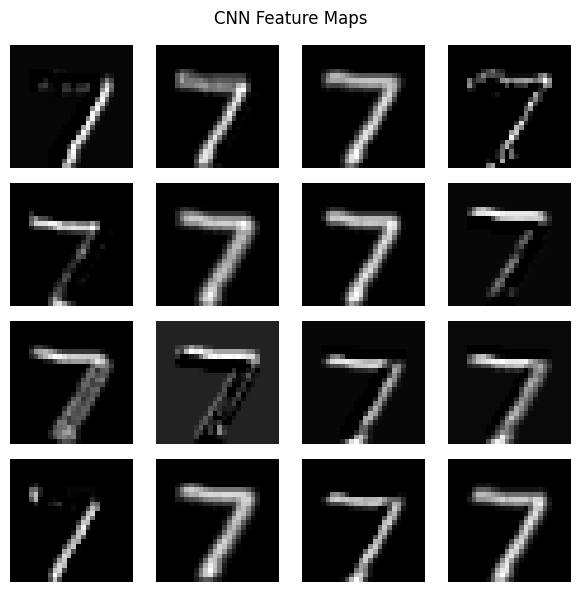

In [84]:
feature_model = models.Model(
    inputs=cnn.inputs,
    outputs=cnn.layers[0].output
)

features = feature_model.predict(X_test[:1], verbose=0)

plt.figure(figsize=(6, 6))

for i in range(16):
    plt.subplot(4, 4, i+1)
    plt.imshow(features[0, :, :, i], cmap='gray')
    plt.axis('off')

plt.suptitle('CNN Feature Maps')
plt.tight_layout()
plt.show()

In [85]:
cnn.save('cnn_mnist_model.h5')
print("CNN model saved successfully!")

CNN model saved successfully!


### Reflection

- **Feature maps:** They show patterns and features detected by CNN filters, such as edges and shapes.
- **Fewer parameters:** The model with the smaller total parameter count has fewer trainable parameters.
- **MaxPooling:** It reduces feature-map dimensions and computation while retaining important features.
- **Why CNN performs better:** CNN learns spatial patterns in images and can recognize shifted or distorted digits more effectively than a plain ANN.
- **Conclusion:** Both models classify handwritten digits, but CNN is generally better suited for image recognition.

# TASK : 4

In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
df = pd.read_csv(url, parse_dates=['Date'])

df['Temp'] = pd.to_numeric(df['Temp'], errors='coerce')
df['Temp'] = df['Temp'].interpolate()

print(df.head())
print(df.dtypes)
print(df.describe())
print("Missing values:", df['Temp'].isna().sum())
print("Dataset shape:", df.shape)

        Date  Temp
0 1981-01-01  20.7
1 1981-01-02  17.9
2 1981-01-03  18.8
3 1981-01-04  14.6
4 1981-01-05  15.8
Date    datetime64[ns]
Temp           float64
dtype: object
                      Date         Temp
count                 3650  3650.000000
mean   1985-12-31 07:12:00    11.177753
min    1981-01-01 00:00:00     0.000000
25%    1983-07-02 06:00:00     8.300000
50%    1985-12-31 12:00:00    11.000000
75%    1988-06-30 18:00:00    14.000000
max    1990-12-31 00:00:00    26.300000
std                    NaN     4.071837
Missing values: 0
Dataset shape: (3650, 2)


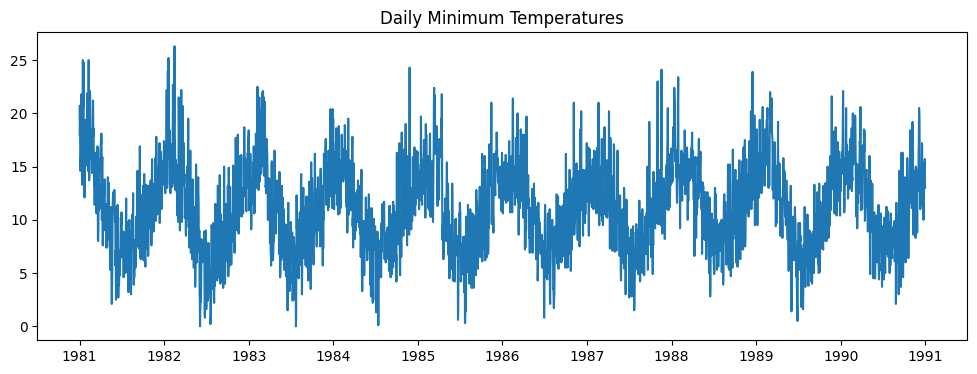

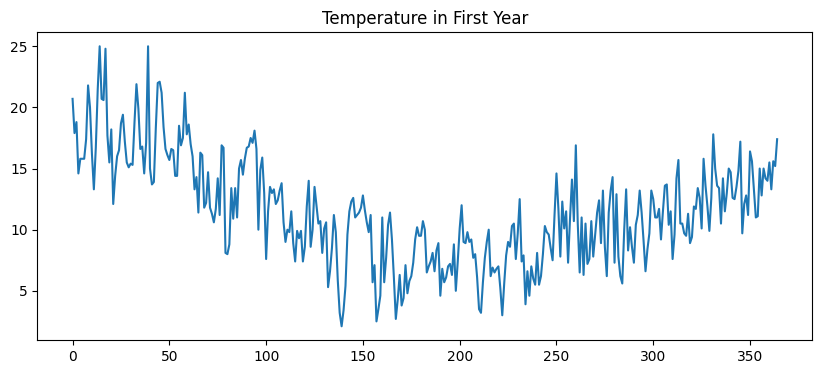

In [87]:
plt.figure(figsize=(12,4))
plt.plot(df['Date'], df['Temp'])
plt.title("Daily Minimum Temperatures")
plt.show()

df['Temp'][:365].plot(figsize=(10,4), title="Temperature in First Year")
plt.show()

In [88]:
data = df['Temp'].values.reshape(-1, 1)
split = int(len(data) * 0.8)

scaler = MinMaxScaler()
scaler.fit(data[:split])
scaled = scaler.transform(data)

train, test = scaled[:split], scaled[split:]

def create_seq(data):
    X, y = [], []
    for i in range(30, len(data)):
        X.append(data[i-30:i])
        y.append(data[i])
    return np.array(X), np.array(y)

X_train, y_train = create_seq(train)
X_test, y_test = create_seq(test)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (2890, 30, 1)
y_train: (2890, 1)
X_test: (700, 30, 1)
y_test: (700, 1)


In [89]:
model = Sequential([
    GRU(32, input_shape=(30, 1)),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.summary()

# Naive baseline: tomorrow = today's temperature
baseline = data[split + 29:-1]
actual = data[split + 30:]

print("Baseline RMSE:", np.sqrt(mean_squared_error(actual, baseline)))

C:\Users\Purvi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

Baseline RMSE: 2.4858657589315984


Epoch 1/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0379 - val_loss: 0.0117
Epoch 2/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0124 - val_loss: 0.0106
Epoch 3/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0109 - val_loss: 0.0099
Epoch 4/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0101 - val_loss: 0.0097
Epoch 5/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0098 - val_loss: 0.0095
Epoch 6/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0095 - val_loss: 0.0093
Epoch 7/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0093 - val_loss: 0.0093
Epoch 8/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0091 - val_loss: 0.0096
Epoch 9/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0091 - val_loss: 0.0091
Epoch 10/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0091 - val_loss: 0.0091
Epoch 11/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0089 - val_loss: 0.0096
Epoch 12/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0090 - val_l

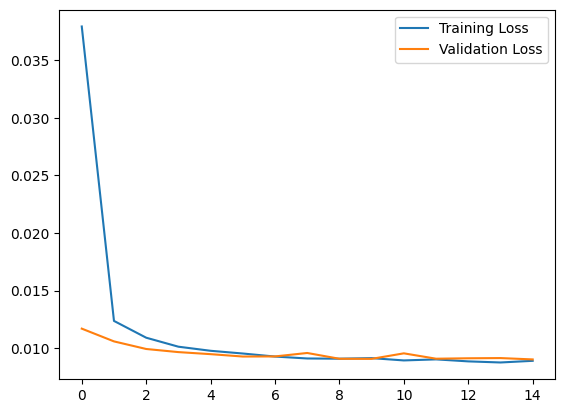

In [90]:
history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.show()

22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
GRU RMSE: 2.2154051976205396
GRU MAE: 1.7381406374658859


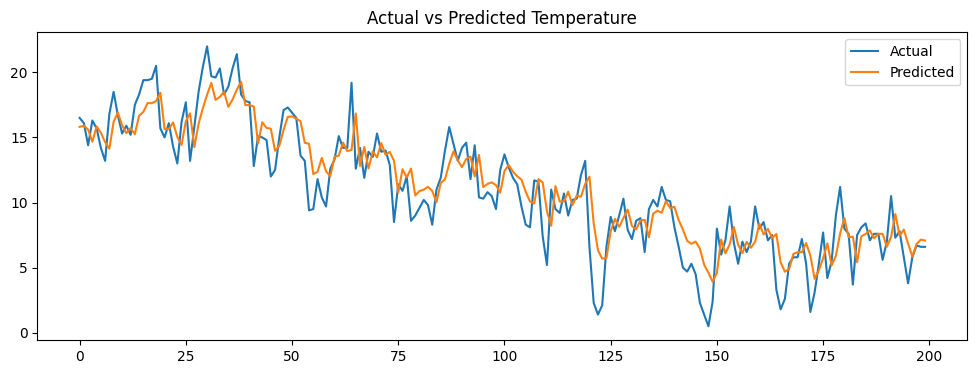

In [91]:
pred = scaler.inverse_transform(model.predict(X_test))
actual = scaler.inverse_transform(y_test)

print("GRU RMSE:", np.sqrt(mean_squared_error(actual, pred)))
print("GRU MAE:", mean_absolute_error(actual, pred))

plt.figure(figsize=(12,4))
plt.plot(actual[:200], label='Actual')
plt.plot(pred[:200], label='Predicted')
plt.legend()
plt.title("Actual vs Predicted Temperature")
plt.show()

In [92]:
base_rmse = np.sqrt(mean_squared_error(actual, baseline))
gru_rmse = np.sqrt(mean_squared_error(actual, pred))

print(pd.DataFrame({
    'Model': ['GRU', 'Naive Baseline'],
    'RMSE': [gru_rmse, base_rmse],
    'MAE': [
        mean_absolute_error(actual, pred),
        mean_absolute_error(actual, baseline)
    ]
}))

            Model      RMSE       MAE
0             GRU  2.215405  1.738141
1  Naive Baseline  2.485866  1.951286


In [93]:
model.save('rnn_temperature_model.h5')
print("Model saved successfully!")

Model saved successfully!


# TASK : 5

In [94]:
!pip install -q transformers torch

import pandas as pd
import matplotlib.pyplot as plt
from transformers import pipeline, set_seed

set_seed(42)


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\Purvi\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip
C:\Users\Purvi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [95]:
fill = pipeline("fill-mask", model="distilbert/distilbert-base-uncased")

sentences = [
    "The capital of India is [MASK].",
    "The Taj Mahal is located in [MASK].",
    "ISRO is India's space [MASK].",
    "Mumbai is a major Indian [MASK].",
    "UPI is used for digital [MASK]."
]

for s in sentences:
    result = fill(s)
    print(s, "->", result[0]['token_str'], result[0]['score'])

C:\Users\Purvi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Purvi\.cache\huggingface\hub\models--distilbert--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\Purv

The capital of India is [MASK]. -> pune 0.15586872398853302
The Taj Mahal is located in [MASK]. -> agra 0.1567147970199585
ISRO is India's space [MASK]. -> agency 0.3758537769317627
Mumbai is a major Indian [MASK]. -> metropolis 0.4598178565502167
UPI is used for digital [MASK]. -> imaging 0.07607609033584595


In [97]:
!pip install -q "transformers==4.44.2" "torch"

  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [83 lines of output]
      Checking for Rust toolchain....
      Rust not found, installing into a temporary directory
      Python reports SOABI: cp313-win_amd64
      Computed rustc target triple: x86_64-pc-windows-msvc
      Installation directory: C:\Users\Purvi\AppData\Local\puccinialin\puccinialin\Cache
      
      Installing rust to C:\Users\Purvi\AppData\Local\puccinialin\puccinialin\Cache\rustup
      warn: installing msvc toolchain without its prerequisites
      error: could not read metadata for file: 'C:\Users\Purvi\AppData\Local\puccinialin\puccinialin\Cache\rustup-init\rustup-init.exe': The system cannot find the path specified. (os error 3)
      Traceback (most recent call last):
        File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_pr

In [100]:
import transformers
print(transformers.__version__)

5.21.0


In [101]:
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForQuestionAnswering

model_name = "distilbert/distilbert-base-cased-distilled-squad"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForQuestionAnswering.from_pretrained(model_name)

data = [
    ("ISRO is headquartered in Bengaluru and was founded in 1969.", "Where is ISRO headquartered?", "Bengaluru"),
    ("ISRO is headquartered in Bengaluru and was founded in 1969.", "When was ISRO founded?", "1969"),
    ("The Taj Mahal is located in Agra and was built by Shah Jahan.", "Where is the Taj Mahal?", "Agra"),
    ("The Taj Mahal is located in Agra and was built by Shah Jahan.", "Who built the Taj Mahal?", "Shah Jahan"),
    ("Indian Railways has its headquarters in New Delhi.", "Where is Indian Railways headquartered?", "New Delhi"),
    ("Indian Railways has its headquarters in New Delhi.", "What is the railway headquarters?", "New Delhi"),
    ("UPI is a digital payment system developed by NPCI in India.", "Who developed UPI?", "NPCI"),
    ("UPI is a digital payment system developed by NPCI in India.", "What is UPI used for?", "payment"),
    ("Mumbai is a city on India's west coast and the capital of Maharashtra.", "Which state has Mumbai as its capital?", "Maharashtra"),
    ("Mumbai is a city on India's west coast and the capital of Maharashtra.", "What is India's national animal?", "")
]

results = []

for context, question, expected in data:
    inputs = tokenizer(question, context, return_tensors="pt",
                        truncation=True, max_length=512)

    with torch.no_grad():
        output = model(**inputs)

    start = output.start_logits.argmax().item()
    end = output.end_logits.argmax().item()

    if end < start:
        end = start

    answer = tokenizer.decode(inputs["input_ids"][0][start:end+1],
                              skip_special_tokens=True)

    correct = bool(expected) and expected.lower() in answer.lower()
    results.append([question, answer, correct])

df = pd.DataFrame(results, columns=["Question", "Predicted Answer", "Correct"])
display(df)
print("Correct answers:", df["Correct"].sum(), "/ 10")

Loading weights: 100%|██████████| 102/102 [00:00<00:00, 694.86it/s]


,Question,Predicted Answer,Correct
0,Where is ISRO headquartered?,Bengaluru,True
1,When was ISRO founded?,1969,True
2,Where is the Taj Mahal?,Agra,True
3,Who built the Taj Mahal?,Shah Jahan,True
4,Where is Indian Railways headquartered?,New Delhi,True
5,What is the railway headquarters?,New Delhi,True
6,Who developed UPI?,NPCI,True
7,What is UPI used for?,a digital payment system,True
8,Which state has Mumbai as its capital?,Maharashtra,True
9,What is India's national animal?,Maharashtra,False


Correct answers: 9 / 10


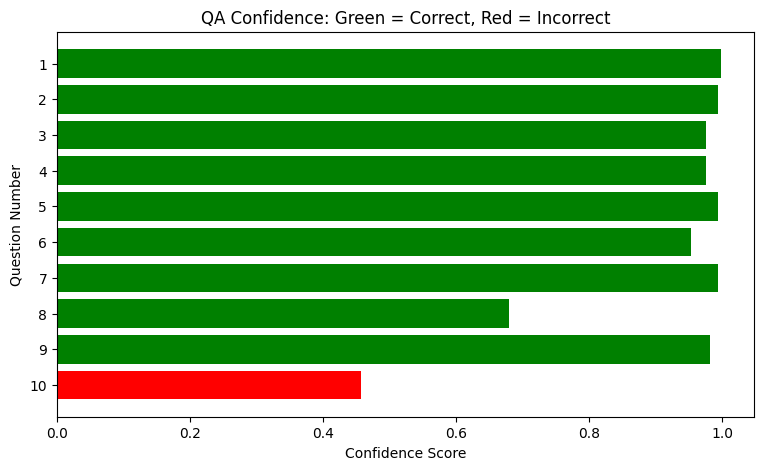

In [104]:
import matplotlib.pyplot as plt

colors = ['green' if x else 'red' for x in df['Correct']]

plt.figure(figsize=(9, 5))
plt.barh(range(1, 11), df['Confidence'], color=colors)
plt.yticks(range(1, 11))
plt.xlabel("Confidence Score")
plt.ylabel("Question Number")
plt.title("QA Confidence: Green = Correct, Red = Incorrect")
plt.gca().invert_yaxis()
plt.show()

In [105]:
from transformers import pipeline, set_seed

set_seed(42)
gen = pipeline("text-generation", model="distilgpt2")

prompts = [
    "India is a country where",
    "Deep learning is",
    "The future of artificial intelligence"
]

for p in prompts:
    output = gen(p, max_new_tokens=30, num_return_sequences=2,
                 do_sample=True,
                 pad_token_id=gen.tokenizer.eos_token_id)
    print("\nPrompt:", p)
    for item in output:
        print(item["generated_text"])

C:\Users\Purvi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Purvi\.cache\huggingface\hub\models--distilgpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 76/7


Prompt: India is a country where
India is a country where more than 3 percent of people are working and we have a great opportunity to help improve our lives and our health.





And
India is a country where there was no threat to Israel from a missile strike. The recent Israeli missile strike in Gaza made it seem that the US and Israeli authorities were being prepared

Prompt: Deep learning is
Deep learning is a new feature of the web. All we have to do is learn what's going on in Web programming.




The Web is
Deep learning is a huge thing. It’s amazing.”

Prompt: The future of artificial intelligence
The future of artificial intelligence is a question of time and space. In the past, the technology came about through a revolution in space and time. From the very beginning, our
The future of artificial intelligence is still somewhat uncertain, but it is likely that artificial intelligence will emerge as a technology that will enable us to create more efficient, more secure, and


In [106]:
prompt = "India is famous for"

for temp in [0.5, 1.5]:
    result = gen(prompt, max_new_tokens=30, do_sample=True,
                 temperature=temp,
                 pad_token_id=gen.tokenizer.eos_token_id)
    print("\nTemperature:", temp)
    print(result[0]["generated_text"])


Temperature: 0.5
India is famous for its low prices and the fact that it has been the face of the global financial crisis for more than two decades. The government has been able to provide

Temperature: 1.5
India is famous for having many positive views among the non-Muslims of Muslim countries but it has suffered a severe setback as the party went on leave. It could not have


In [107]:
context = "ISRO is headquartered in Bengaluru, India."
question = "ISRO ka headquarters kahan hai?"

inputs = tokenizer(question, context, return_tensors="pt")

with torch.no_grad():
    output = model(**inputs)

start = output.start_logits.argmax().item()
end = max(start, output.end_logits.argmax().item())

print("Answer:", tokenizer.decode(
    inputs["input_ids"][0][start:end+1],
    skip_special_tokens=True
))

Answer: Bengaluru


Fill-Mask: Predicts missing words based on context.



Encoder vs Decoder: BERT-style encoders understand text; GPT-style decoders generate text.



Self-attention: Helps a model understand relationships between words.



Extractive QA: Selects an answer from the given paragraph.



Temperature: Lower temperature generally produces more predictable text; higher temperature produces more varied text.



Limitations: Models can produce incorrect answers or fluent but meaningless text.

# TASK : 6

In [108]:
import pandas as pd

results = pd.DataFrame({
    "Step / Topic": ["ANN", "OpenCV", "CNN", "RNN", "Transformer"],
    "Task Type": [
        "Classification",
        "Image Processing / Face Detection",
        "Image Classification",
        "Temperature Forecasting",
        "Fill-Mask / QA / Text Generation"
    ],
    "Dataset Used": [
        "Enter your ANN dataset",
        "Your test images",
        "MNIST (60,000 training images)",
        "Daily Minimum Temperatures (3,650 days)",
        "5 India-related paragraphs"
    ],
    "Key Metric": [
        "Accuracy (%)",
        "Faces detected",
        "Accuracy (%)",
        "RMSE (°C)",
        "Correct answers (/10)"
    ],
    "Result Achieved": ["Enter result", "Enter result", "Enter result",
                        "Enter result", "Enter result"],
    "Time Taken": ["Enter minutes"] * 5
})

display(results)

,Step / Topic,Task Type,Dataset Used,Key Metric,Result Achieved,Time Taken
0,ANN,Classification,Enter your ANN dataset,Accuracy (%),Enter result,Enter minutes
1,OpenCV,Image Processing / Face Detection,Your test images,Faces detected,Enter result,Enter minutes
2,CNN,Image Classification,"MNIST (60,000 training images)",Accuracy (%),Enter result,Enter minutes
3,RNN,Temperature Forecasting,"Daily Minimum Temperatures (3,650 days)",RMSE (°C),Enter result,Enter minutes
4,Transformer,Fill-Mask / QA / Text Generation,5 India-related paragraphs,Correct answers (/10),Enter result,Enter minutes


In [109]:
results.to_csv("results_summary.csv", index=False)
print("Results saved!")

Results saved!


## Written Reflection

- The most challenging task was the RNN because preparing time-series sequences and evaluating predictions required careful steps.
- The best result depended on the model's performance and the time required to build it.
- With more time, I would improve my ANN by tuning the number of layers and neurons.
- CNNs often use fewer parameters than fully connected ANNs on images because convolutional filters share weights and focus on local patterns.
- GRU models process sequential data using gates, while Transformers use self-attention to model relationships between tokens.
- GPT-style models can generate incorrect facts. I would verify outputs using trusted sources and human review.
- Haar cascade face detection is useful for simple, fast tasks, while deep learning can perform better in more complex conditions.
- This practical helped me understand classification, image processing, neural networks, time-series prediction, and pretrained Transformers.

In [110]:
requirements = """tensorflow
keras
opencv-python
scikit-image
scikit-learn
transformers
torch
pandas
numpy
matplotlib
seaborn
"""

with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(requirements)

print("requirements.txt created!")

requirements.txt created!


In [111]:
report = """# Summary Report

## Introduction
This practical covered five projects using ANN, OpenCV, CNN, RNN and Transformers.

## Tasks and Datasets
ANN was used for classification. OpenCV was used for image processing and face detection.
CNN was evaluated on MNIST handwritten digits. RNN was used to predict daily minimum
temperatures in Melbourne. Transformers were used for fill-mask, question answering
and text generation with India-related examples.

## Results
Refer to results_summary.csv for the actual metrics and time taken for each project.
The results should be filled in using the outputs obtained from the notebook.

## Learning
I learned how neural networks perform classification, how OpenCV processes images,
how CNNs learn image features, and how recurrent networks handle sequential data.
I also learned how pretrained Transformer models understand and generate text.

## Future Improvements
I would tune model parameters, compare additional architectures, improve evaluation,
and test the models on more diverse datasets. I would also verify generated text
against reliable sources before using it in real applications.
"""

with open("summary_report.md", "w", encoding="utf-8") as f:
    f.write(report)

print("summary_report.md created!")

summary_report.md created!
